# O modelo de mix de marketing recupera o efeito de cada canal?

O gestor recebe um gráfico de "contribuição por canal" e realoca a verba. Este notebook mede quando esse gráfico
merece confiança, do único jeito em que isso pode ser medido: num mundo simulado, em que o efeito verdadeiro de cada
canal é conhecido.

**Os dados são simulados, de propósito.** Nenhum número aqui descreve uma operação real. O gerador está em
`src/mmm_confiar/dados.py`; o modelo, o bootstrap e a otimização, em `src/mmm_confiar/`, escritos em NumPy/SciPy e
conferidos em `tests/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from mmm_confiar import analise, dados, graficos, linha_de_base, modelo, otimizacao

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)
resultados = json.loads(Path("reports/resultados.json").read_text(encoding="utf-8"))
cenarios = resultados["cenarios"]


def mostrar(figura):
    display(figura)
    plt.close(figura)


def tabela(chaves, metricas):
    linhas = {}
    for chave in chaves:
        m = cenarios[chave]["metricas"]
        linhas[cenarios[chave]["rotulo"]] = {nome: f"{m[k]['media']:.2f}  [{m[k]['inferior']:.2f}; {m[k]['superior']:.2f}]" for nome, k in metricas.items()}
    return pd.DataFrame.from_dict(linhas, orient="index")

## 1. Um mundo de exemplo

Vendas semanais de um anunciante com quatro canais (R$ mil por semana). O que o analista vê é a primeira tabela; a
segunda é o gabarito, que só o gerador conhece: quanto da venda de cada semana veio da base, da promoção, de cada
canal e do acaso.

In [2]:
chave, semente = analise.EXEMPLO
serie = dados.gerar(analise.POR_CHAVE[chave].cenario, semente)
visto, gabarito = dados.carregar_exemplo()  # os mesmos dados, versionados em data/
assert np.allclose(visto["vendas"], serie.vendas, atol=1e-2)
display(visto.head())
display(gabarito.head())
pd.DataFrame(dados.gabarito(serie)["canais"]).T

,semana,vendas,promocao,gasto_busca,gasto_social,gasto_video,gasto_afiliados
0,2024-01-01,"1,433.70",0,54.19,61.43,32.89,11.50
1,2024-01-08,"1,492.73",0,55.90,63.42,32.52,11.30
2,2024-01-15,"1,453.99",0,50.31,46.56,39.52,10.34
3,2024-01-22,"1,399.62",0,42.54,34.12,36.80,10.81
4,2024-01-29,"1,390.49",0,34.32,32.93,27.51,10.64


,semana,base,promocao,choque,ruido,venda_busca,venda_social,venda_video,venda_afiliados
0,2024-01-01,"1,246.38",0.00,-11.66,-31.34,95.74,75.72,26.62,32.23
1,2024-01-08,"1,226.99",0.00,1.76,27.77,98.07,79.48,26.52,32.14
2,2024-01-15,"1,205.94",0.00,16.39,6.30,95.57,71.90,27.20,30.68
3,2024-01-22,"1,184.08",0.00,16.99,-11.74,90.22,61.45,27.36,31.27
4,2024-01-29,"1,162.26",0.00,18.90,11.99,82.70,57.11,26.46,31.06


,gasto_de_referencia,venda_semanal_no_gasto_de_referencia,retencao_do_adstock,meia_saturacao_em_multiplos_do_gasto_de_referencia,expoente_da_hill,gasto_total_no_periodo,venda_total_gerada_no_periodo,roi_verdadeiro
busca,40.00,86.24,0.21,0.80,1.00,"3,726.36","8,370.90",2.25
social,35.00,57.51,0.29,1.81,1.00,"3,337.25","5,542.76",1.66
video,30.00,25.44,0.65,0.74,1.00,"2,784.49","2,439.13",0.88
afiliados,10.00,29.94,0.09,1.45,1.00,"1,029.45","3,087.28",3.00


Os problemas da vida real estão no gerador: a verba inteira sobe na alta temporada (os gastos andam juntos), o
canal de afiliados quase não varia, e num dos cenários o gasto de busca responde à demanda.

In [3]:
gasto = visto[[f"gasto_{c}" for c in dados.CANAIS]]
display(gasto.corr().round(2))
(gasto.std() / gasto.mean()).rename("desvio / média do gasto").to_frame().T

,gasto_busca,gasto_social,gasto_video,gasto_afiliados
gasto_busca,1.00,0.57,0.37,0.56
gasto_social,0.57,1.00,0.61,0.50
gasto_video,0.37,0.61,1.00,0.39
gasto_afiliados,0.56,0.50,0.39,1.00


,gasto_busca,gasto_social,gasto_video,gasto_afiliados
desvio / média do gasto,0.30,0.34,0.49,0.10


## 2. O modelo ajustado nesse exemplo

O MMM (adstock geométrico, saturação de Hill, efeitos não negativos, penalidade na forma da curva) é ajustado por
um Levenberg-Marquardt próprio, a partir de oito pontos de partida. A incerteza vem de 200 réplicas de bootstrap em
blocos. Ao lado, as duas alternativas simples.

In [4]:
exemplo = analise.exemplo(serie)
print(f"pontos de partida que chegaram ao mesmo ótimo: {exemplo['partidas_no_mesmo_otimo']:.0%}")
exemplo["tabela"][["venda verdadeira", "MMM", "MMM IC 95% inferior", "MMM IC 95% superior", "regressão linear", "proporcional ao gasto", "ROI verdadeiro", "ROI MMM"]]

pontos de partida que chegaram ao mesmo ótimo: 100%


,venda verdadeira,MMM,MMM IC 95% inferior,MMM IC 95% superior,regressão linear,proporcional ao gasto,ROI verdadeiro,ROI MMM
Busca,"8,370.90","12,954.86","8,125.77","21,120.97","5,370.17","8,270.10",2.25,3.48
Social,"5,542.76","11,186.22","4,352.24","17,131.57","3,226.76","7,406.52",1.66,3.35
Vídeo,"2,439.13",0.00,0.00,"4,248.38",-210.44,"6,179.76",0.88,0.00
Afiliados,"3,087.28",0.00,0.00,"16,405.73","-4,046.31","2,284.70",3.00,0.00


Nesta série o modelo deu a busca e a social o dobro do que elas geraram e zerou vídeo e afiliados. Os intervalos
são honestos (cobrem o valor verdadeiro), mas tão largos que não distinguem um canal bom de um ruim.

A figura mostra o porquê. Os dados só informam a inclinação da curva na faixa de gasto observada (fundo cinza). A
contribuição do canal é a altura da curva no gasto de hoje, medida a partir do gasto zero, onde não há dado.

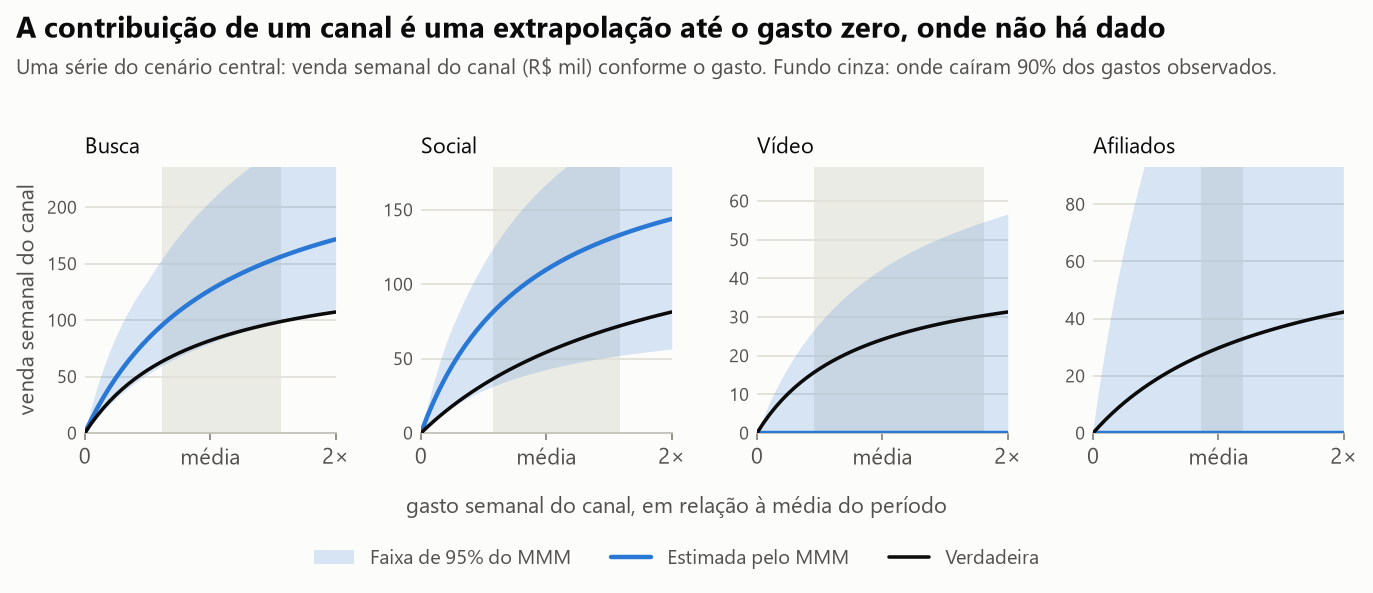

In [5]:
mostrar(graficos.curvas_do_exemplo(exemplo))

## 3. O estudo de recuperação

Uma série só não prova nada. `scripts/rodar_analise.py` repete o exercício em 15 cenários, com 48 séries em cada um
(a mesma semente dá o mesmo mundo e o mesmo ruído em todos os cenários). Em cada série mede:

- **erro de contribuição**: venda atribuída ao canal errado ou inventada, em fração da venda de mídia verdadeira;
- **pares invertidos**: parte dos pares de canais que o método ordena ao contrário pelo ROI (0,5 = cara ou coroa);
- **cobertura** dos intervalos de 80% e de 95%;
- **decisão**: o ganho de venda de mídia ao realocar a verba pelo método, avaliado nas curvas verdadeiras.

Os colchetes são o intervalo de 95% do erro de Monte Carlo (reamostrando as 48 sementes).

In [6]:
observacionais = ["laboratorio", "quatro_anos", "colinearidade_baixa", "central", "um_ano", "colinearidade_alta", "busca_demanda", "dificil", "forma_errada"]
tabela(observacionais, {"MMM": "mmm_erro_contribuicao", "regressão linear": "linear_erro_contribuicao", "proporcional ao gasto": "proporcional_erro_contribuicao",
                        "MMM - linear": "mmm_menos_linear_erro_contribuicao"})

,MMM,regressão linear,proporcional ao gasto,MMM - linear
"Laboratório: 4 anos, colinearidade baixa, variação deliberada, 1/4 do ruído",0.10 [0.09; 0.11],0.56 [0.55; 0.58],0.31 [0.30; 0.32],-0.46 [-0.48; -0.45]
Histórico de 4 anos,0.77 [0.63; 0.92],0.69 [0.66; 0.72],0.53 [0.44; 0.64],0.08 [-0.05; 0.22]
Colinearidade baixa,0.86 [0.64; 1.11],0.69 [0.65; 0.73],0.68 [0.50; 0.90],0.17 [-0.04; 0.41]
"Central: 2 anos, colinearidade média",0.93 [0.73; 1.16],0.74 [0.70; 0.79],0.65 [0.50; 0.84],0.19 [-0.01; 0.40]
Histórico de 1 ano,1.16 [0.94; 1.45],0.84 [0.79; 0.89],0.74 [0.55; 0.99],0.32 [0.10; 0.63]
Colinearidade alta,1.23 [1.00; 1.48],0.97 [0.88; 1.07],0.66 [0.51; 0.82],0.27 [0.07; 0.48]
Busca responde à demanda,0.82 [0.71; 0.95],0.63 [0.59; 0.67],0.47 [0.37; 0.60],0.20 [0.08; 0.33]
Difícil: colinearidade alta + busca responde à demanda,1.09 [1.00; 1.20],0.76 [0.71; 0.82],0.37 [0.31; 0.45],0.33 [0.22; 0.45]
"Forma errada (saturação em S, pico atrasado)",1.62 [1.37; 1.92],0.71 [0.66; 0.77],1.31 [1.05; 1.59],0.91 [0.66; 1.19]


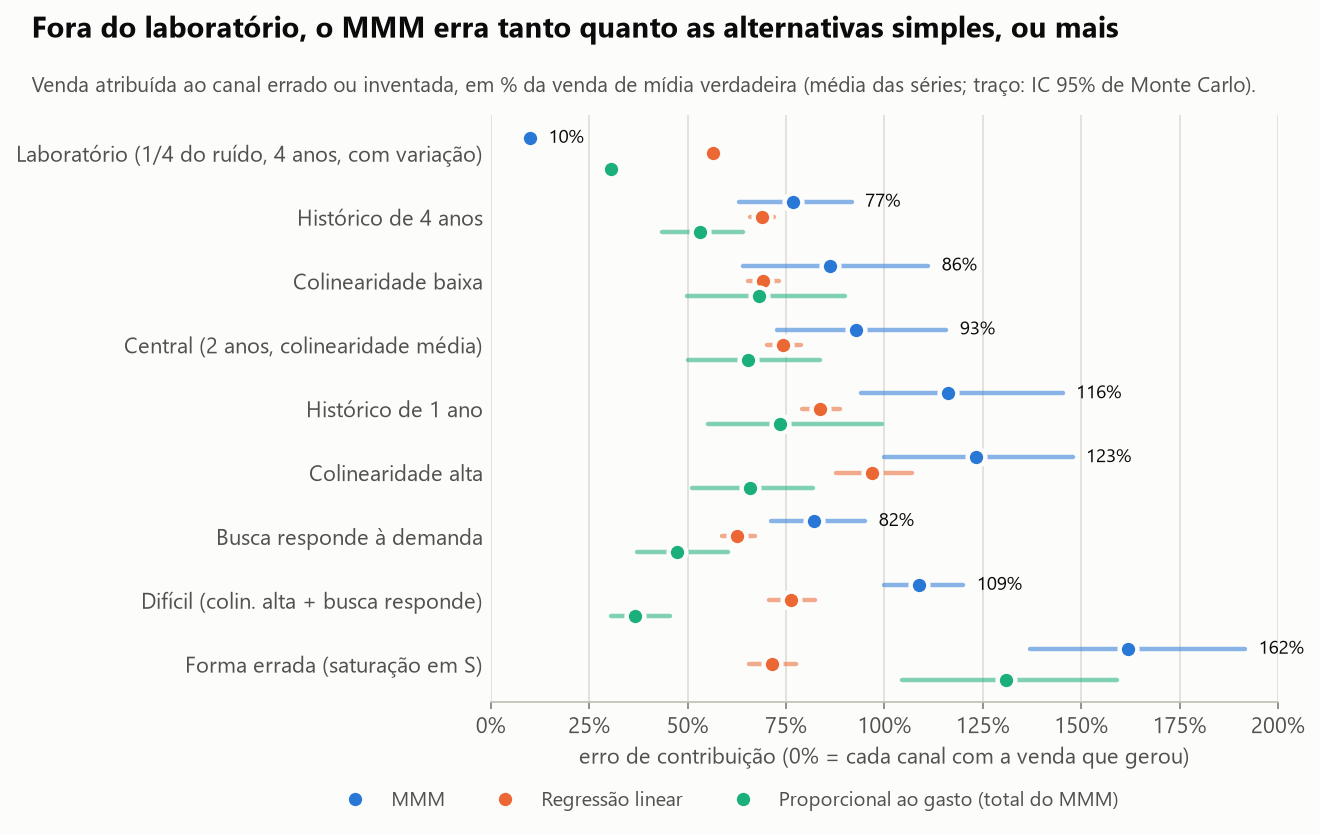

In [7]:
mostrar(graficos.erro_por_cenario(cenarios))

No laboratório (quatro anos, gastos que variam de forma independente, um quarto do ruído) o modelo recupera os
canais: é a prova de que o código está certo. Fora dele, o MMM não bate a regressão linear, e repartir o total que
ele mesmo estima na proporção do gasto erra menos do que a repartição do modelo.

A ordem dos canais conta a mesma história.

In [8]:
tabela(observacionais, {"pares invertidos: MMM": "mmm_pares_invertidos", "pares invertidos: linear": "linear_pares_invertidos",
                        "melhor canal errado: MMM": "mmm_melhor_canal_errado", "melhor canal errado: linear": "linear_melhor_canal_errado"})

,pares invertidos: MMM,pares invertidos: linear,melhor canal errado: MMM,melhor canal errado: linear
"Laboratório: 4 anos, colinearidade baixa, variação deliberada, 1/4 do ruído",0.05 [0.03; 0.08],0.10 [0.07; 0.13],0.12 [0.04; 0.23],0.12 [0.04; 0.23]
Histórico de 4 anos,0.34 [0.27; 0.41],0.24 [0.17; 0.31],0.52 [0.38; 0.67],0.38 [0.25; 0.52]
Colinearidade baixa,0.32 [0.26; 0.39],0.28 [0.22; 0.35],0.50 [0.35; 0.65],0.44 [0.31; 0.58]
"Central: 2 anos, colinearidade média",0.39 [0.33; 0.45],0.30 [0.22; 0.37],0.54 [0.40; 0.69],0.46 [0.31; 0.60]
Histórico de 1 ano,0.43 [0.36; 0.50],0.41 [0.32; 0.49],0.54 [0.40; 0.69],0.54 [0.40; 0.69]
Colinearidade alta,0.46 [0.40; 0.53],0.29 [0.23; 0.36],0.65 [0.50; 0.79],0.31 [0.19; 0.46]
Busca responde à demanda,0.42 [0.35; 0.49],0.38 [0.31; 0.45],0.77 [0.65; 0.90],0.71 [0.58; 0.83]
Difícil: colinearidade alta + busca responde à demanda,0.46 [0.42; 0.49],0.38 [0.31; 0.45],0.92 [0.83; 0.98],0.67 [0.52; 0.81]
"Forma errada (saturação em S, pico atrasado)",0.39 [0.32; 0.47],0.28 [0.22; 0.35],0.52 [0.38; 0.67],0.33 [0.21; 0.48]


## 4. Os intervalos

,cobertura 80%,cobertura 95%,largura do IC 95% / valor verdadeiro,cobertura 95% da linear
"Laboratório: 4 anos, colinearidade baixa, variação deliberada, 1/4 do ruído",0.75 [0.68; 0.82],0.89 [0.83; 0.93],0.49 [0.47; 0.52],0.09 [0.06; 0.12]
Histórico de 4 anos,0.79 [0.73; 0.85],0.97 [0.95; 0.99],2.45 [2.31; 2.61],0.29 [0.26; 0.32]
Colinearidade baixa,0.75 [0.68; 0.81],0.91 [0.86; 0.94],2.95 [2.73; 3.18],0.31 [0.27; 0.35]
"Central: 2 anos, colinearidade média",0.79 [0.72; 0.84],0.94 [0.91; 0.97],3.13 [2.88; 3.39],0.36 [0.32; 0.41]
Histórico de 1 ano,0.86 [0.80; 0.91],0.95 [0.92; 0.98],4.69 [4.24; 5.14],0.51 [0.45; 0.56]
Colinearidade alta,0.86 [0.80; 0.91],1.00 [1.00; 1.00],4.29 [3.97; 4.62],0.63 [0.59; 0.67]
Busca responde à demanda,0.60 [0.55; 0.65],0.72 [0.70; 0.74],2.13 [1.93; 2.35],0.34 [0.30; 0.40]
Difícil: colinearidade alta + busca responde à demanda,0.35 [0.31; 0.40],0.55 [0.51; 0.59],1.66 [1.54; 1.77],0.48 [0.43; 0.53]
"Forma errada (saturação em S, pico atrasado)",0.62 [0.57; 0.67],0.78 [0.72; 0.83],4.26 [3.89; 4.66],0.52 [0.46; 0.58]


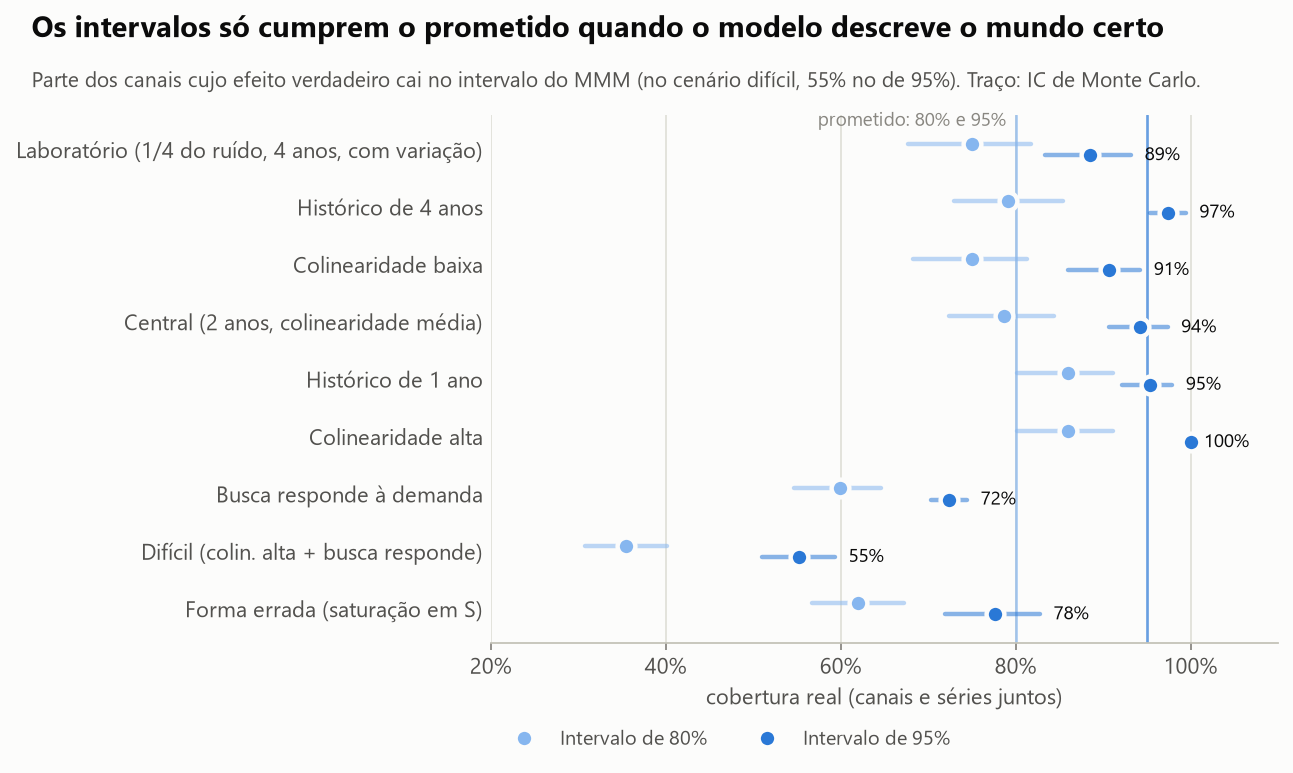

In [9]:
display(tabela(observacionais, {"cobertura 80%": "mmm_cobertura_80", "cobertura 95%": "mmm_cobertura_95", "largura do IC 95% / valor verdadeiro": "mmm_largura_95",
                                "cobertura 95% da linear": "linear_cobertura_95"}))
mostrar(graficos.cobertura(cenarios))

Com a forma certa e sem o canal que responde à demanda, o bootstrap em blocos entrega a cobertura prometida. O
preço é a largura: no cenário central o intervalo de 95% tem cerca de três vezes o tamanho do efeito que mede.
Quando a busca responde à demanda, ou quando a forma da curva está errada, o intervalo fica confiante no lugar errado.

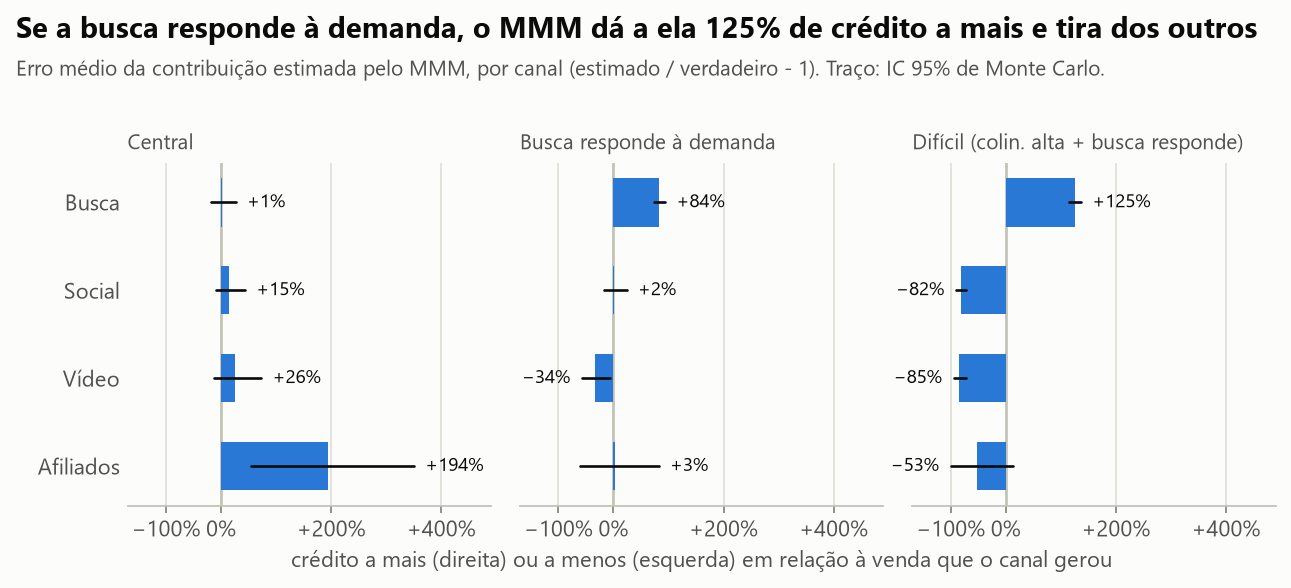

,central,busca_demanda,dificil
busca,94%,2%,0%
social,94%,92%,29%
video,94%,98%,92%
afiliados,96%,98%,100%


In [10]:
mostrar(graficos.credito_por_canal(cenarios))
pd.DataFrame({c: {canal: f"{b['cobertura_95']['media']:.0%}" for canal, b in cenarios[c]["por_canal"]["mmm"].items()} for c in ["central", "busca_demanda", "dificil"]})

## 5. Da medição à decisão

A verba do mundo de referência está mal repartida de propósito: realocando com as curvas verdadeiras, a venda de
mídia sobe cerca de 3,5%. A tabela mostra quanto se ganha (ou perde) realocando pelas curvas estimadas, com a verba
total fixa e cada canal limitado a 50% a mais ou a menos.

,ganho possível,ganho pelo MMM,ganho pela linear,MMM pior que não mexer,linear pior que não mexer
"Laboratório: 4 anos, colinearidade baixa, variação deliberada, 1/4 do ruído",0.04 [0.03; 0.04],0.03 [0.03; 0.04],0.02 [0.01; 0.02],0.00 [0.00; 0.00],0.25 [0.12; 0.38]
Histórico de 4 anos,0.04 [0.03; 0.04],0.00 [-0.01; 0.01],-0.00 [-0.01; 0.01],0.40 [0.25; 0.54],0.42 [0.27; 0.56]
Colinearidade baixa,0.04 [0.03; 0.04],-0.00 [-0.01; 0.01],-0.01 [-0.02; 0.00],0.48 [0.33; 0.62],0.65 [0.50; 0.77]
"Central: 2 anos, colinearidade média",0.04 [0.03; 0.04],-0.01 [-0.02; -0.00],-0.01 [-0.02; -0.00],0.69 [0.56; 0.81],0.69 [0.56; 0.81]
Histórico de 1 ano,0.04 [0.03; 0.04],-0.02 [-0.03; -0.01],-0.03 [-0.04; -0.01],0.67 [0.52; 0.79],0.73 [0.60; 0.85]
Colinearidade alta,0.04 [0.03; 0.04],-0.04 [-0.05; -0.03],-0.03 [-0.04; -0.02],0.83 [0.73; 0.94],0.83 [0.73; 0.94]
Busca responde à demanda,0.04 [0.03; 0.04],-0.03 [-0.04; -0.02],-0.03 [-0.04; -0.03],0.83 [0.71; 0.94],0.94 [0.85; 1.00]
Difícil: colinearidade alta + busca responde à demanda,0.04 [0.03; 0.04],-0.05 [-0.06; -0.04],-0.04 [-0.05; -0.03],0.98 [0.94; 1.00],0.92 [0.83; 0.98]
"Forma errada (saturação em S, pico atrasado)",0.12 [0.11; 0.14],0.05 [0.03; 0.07],-0.01 [-0.04; 0.02],0.23 [0.12; 0.35],0.56 [0.42; 0.71]


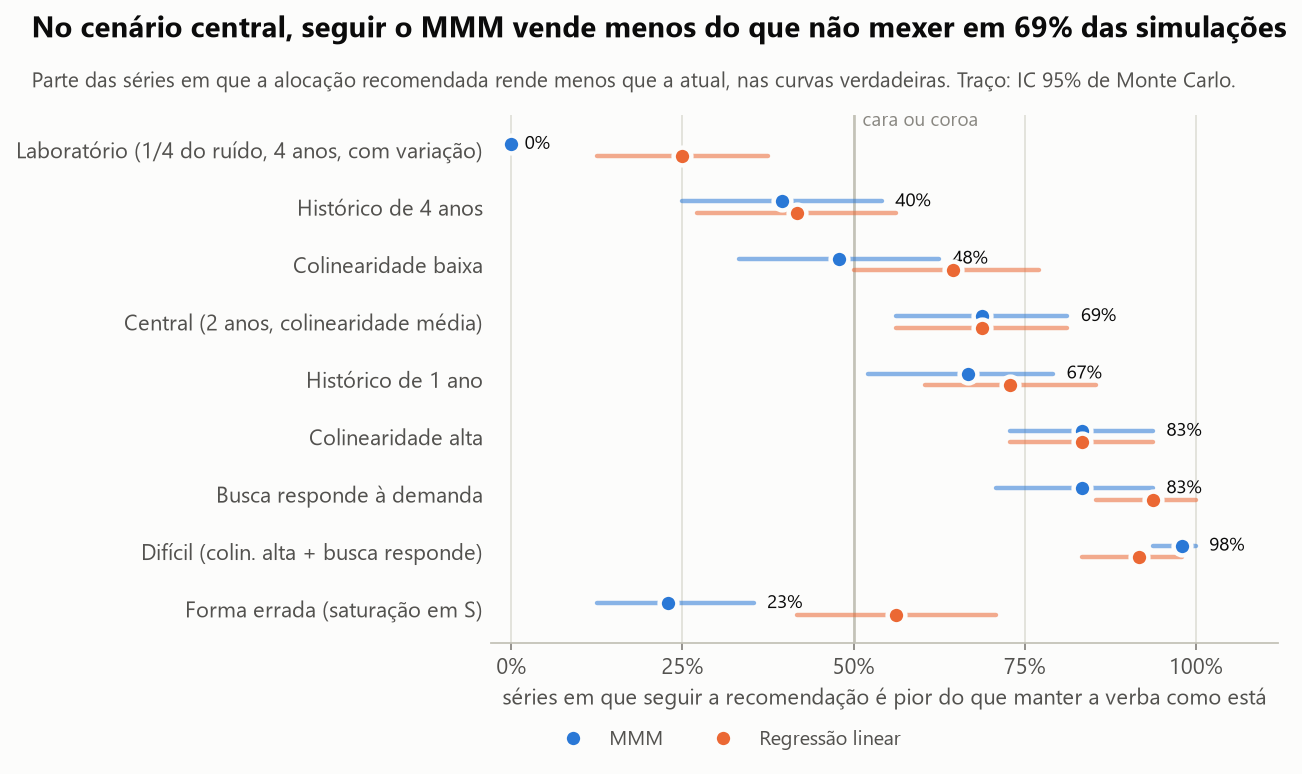

In [11]:
display(tabela(observacionais, {"ganho possível": "ganho_possivel", "ganho pelo MMM": "mmm_ganho", "ganho pela linear": "linear_ganho",
                                "MMM pior que não mexer": "mmm_pior_que_nao_mexer", "linear pior que não mexer": "linear_pior_que_nao_mexer"}))
mostrar(graficos.pior_que_nao_mexer(cenarios))

In [12]:
pd.DataFrame({c: cenarios[c]["alocacao_media_sobre_a_atual"]["mmm"] for c in ["central", "dificil", "laboratorio"]}).assign(
    **{"ótima (central)": pd.Series(cenarios["central"]["alocacao_media_sobre_a_atual"]["otima"])})

,central,dificil,laboratorio,ótima (central)
busca,1.12,1.50,0.99,0.97
social,1.05,0.79,1.27,1.32
video,0.77,0.70,0.55,0.52
afiliados,1.04,0.56,1.44,1.43


A alocação certa corta vídeo pela metade e reforça social e afiliados. No cenário difícil o modelo manda pôr 50%
a mais em busca, o canal que ele superestima.

## 6. O que conserta

,erro de contribuição,pares invertidos,cobertura 95%,ganho pelo MMM,pior que não mexer
"Central: 2 anos, colinearidade média",0.93 [0.73; 1.16],0.39 [0.33; 0.45],0.94 [0.91; 0.97],-0.01 [-0.02; -0.00],0.69 [0.56; 0.81]
Central + variação deliberada,0.41 [0.36; 0.47],0.28 [0.21; 0.34],0.90 [0.85; 0.94],0.01 [0.00; 0.02],0.33 [0.21; 0.46]
Central + calibração por experimento,0.40 [0.34; 0.48],0.20 [0.15; 0.26],0.95 [0.92; 0.97],0.01 [-0.00; 0.02],0.35 [0.23; 0.48]
Difícil: colinearidade alta + busca responde à demanda,1.09 [1.00; 1.20],0.46 [0.42; 0.49],0.55 [0.51; 0.59],-0.05 [-0.06; -0.04],0.98 [0.94; 1.00]
Difícil + variação deliberada,0.34 [0.30; 0.38],0.21 [0.14; 0.27],0.81 [0.74; 0.86],-0.01 [-0.02; -0.01],0.65 [0.50; 0.77]
Difícil + calibração por experimento,0.54 [0.51; 0.57],0.19 [0.15; 0.22],0.77 [0.71; 0.83],-0.03 [-0.04; -0.02],0.94 [0.85; 1.00]


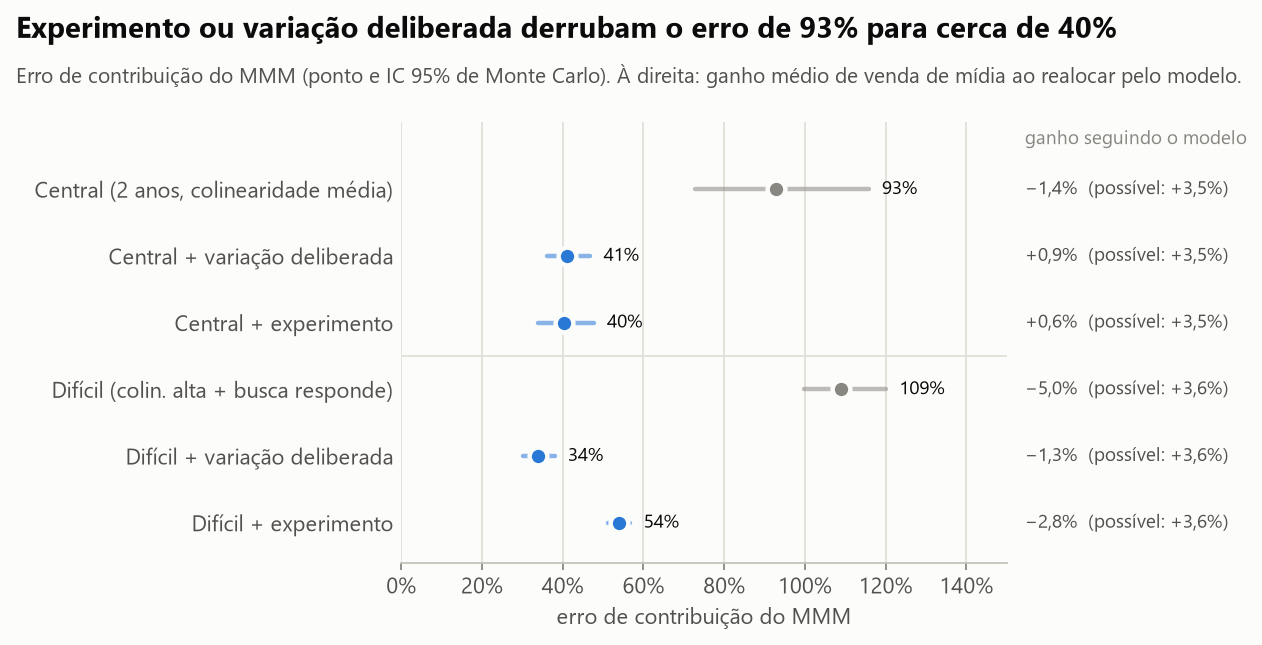

In [13]:
conserto = ["central", "central_variacao", "central_experimento", "dificil", "dificil_variacao", "dificil_experimento"]
display(tabela(conserto, {"erro de contribuição": "mmm_erro_contribuicao", "pares invertidos": "mmm_pares_invertidos", "cobertura 95%": "mmm_cobertura_95",
                          "ganho pelo MMM": "mmm_ganho", "pior que não mexer": "mmm_pior_que_nao_mexer"}))
mostrar(graficos.conserto(cenarios))

In [14]:
pd.DataFrame({par: {m: f"{v['media']:+.2f}  [{v['inferior']:+.2f}; {v['superior']:+.2f}]" for m, v in bloco.items()}
              for par, bloco in resultados["diferencas_entre_cenarios"].items()}).T

,mmm_erro_contribuicao,mmm_erro_roi,mmm_pares_invertidos,mmm_cobertura_95,mmm_ganho,mmm_pior_que_nao_mexer
central -> colinearidade_alta,+0.31 [+0.20; +0.41],+0.22 [+0.12; +0.30],+0.08 [+0.03; +0.13],+0.06 [+0.03; +0.09],-0.03 [-0.04; -0.01],+0.15 [+0.02; +0.27]
central -> um_ano,+0.23 [-0.03; +0.50],+0.22 [+0.07; +0.36],+0.04 [-0.04; +0.12],+0.01 [-0.04; +0.06],-0.01 [-0.02; +0.00],-0.02 [-0.19; +0.15]
central -> quatro_anos,-0.16 [-0.33; +0.00],-0.11 [-0.24; +0.01],-0.05 [-0.14; +0.05],+0.03 [-0.01; +0.07],+0.02 [+0.00; +0.03],-0.29 [-0.48; -0.10]
central -> busca_demanda,-0.11 [-0.25; +0.03],+0.08 [-0.05; +0.20],+0.03 [-0.05; +0.10],-0.22 [-0.26; -0.18],-0.01 [-0.03; -0.00],+0.15 [-0.02; +0.31]
central -> forma_errada,+0.69 [+0.57; +0.82],+0.59 [+0.46; +0.72],+0.01 [-0.05; +0.07],-0.17 [-0.22; -0.11],+0.06 [+0.05; +0.08],-0.46 [-0.60; -0.33]
central -> central_variacao,-0.52 [-0.74; -0.32],-0.26 [-0.39; -0.14],-0.11 [-0.20; -0.02],-0.05 [-0.10; +0.01],+0.02 [+0.01; +0.03],-0.35 [-0.52; -0.19]
central -> central_experimento,-0.53 [-0.74; -0.33],-0.38 [-0.51; -0.28],-0.19 [-0.26; -0.12],+0.01 [-0.03; +0.04],+0.02 [+0.01; +0.03],-0.33 [-0.48; -0.19]
dificil -> dificil_variacao,-0.75 [-0.86; -0.66],-0.60 [-0.66; -0.54],-0.26 [-0.33; -0.18],+0.26 [+0.18; +0.32],+0.04 [+0.03; +0.05],-0.33 [-0.48; -0.21]
dificil -> dificil_experimento,-0.55 [-0.66; -0.46],-0.44 [-0.48; -0.39],-0.27 [-0.31; -0.24],+0.22 [+0.17; +0.27],+0.02 [+0.01; +0.03],-0.04 [-0.10; +0.00]
central -> metade_do_ruido,-0.38 [-0.49; -0.27],-0.23 [-0.31; -0.17],-0.06 [-0.10; -0.03],-0.03 [-0.07; +0.01],+0.02 [+0.02; +0.03],-0.27 [-0.42; -0.15]


A última tabela traz as diferenças semente a semente (mesmo mundo, mesmo ruído, só o cenário muda).

Variação deliberada de gasto e calibração por experimento cortam o erro de contribuição para menos da metade. A
decisão melhora menos: o experimento usado aqui mede o efeito total do canal, e a realocação depende da inclinação
da curva. No cenário difícil, mesmo calibrado, o modelo ainda manda reforçar a busca.

## 7. Sensibilidade

In [15]:
tabela(["central", "central_penalidade_roi", "metade_do_ruido", "laboratorio"], {
    "erro de contribuição": "mmm_erro_contribuicao", "proporcional ao gasto": "proporcional_erro_contribuicao", "pares invertidos": "mmm_pares_invertidos",
    "cobertura 95%": "mmm_cobertura_95", "ganho pelo MMM": "mmm_ganho"})

,erro de contribuição,proporcional ao gasto,pares invertidos,cobertura 95%,ganho pelo MMM
"Central: 2 anos, colinearidade média",0.93 [0.73; 1.16],0.65 [0.50; 0.84],0.39 [0.33; 0.45],0.94 [0.91; 0.97],-0.01 [-0.02; -0.00]
Central + penalidade no ROI,0.46 [0.40; 0.53],0.40 [0.37; 0.43],0.46 [0.41; 0.51],0.72 [0.69; 0.75],-0.01 [-0.02; -0.00]
Central com metade do ruído,0.55 [0.44; 0.68],0.44 [0.38; 0.52],0.32 [0.26; 0.39],0.91 [0.87; 0.95],0.01 [-0.00; 0.02]
"Laboratório: 4 anos, colinearidade baixa, variação deliberada, 1/4 do ruído",0.10 [0.09; 0.11],0.31 [0.30; 0.32],0.05 [0.03; 0.08],0.89 [0.83; 0.93],0.03 [0.03; 0.04]


- **Penalidade no ROI** (os valores da distribuição a priori padrão do Meridian): o erro cai porque todos os
  canais são puxados para o mesmo ROI, o que aproxima o modelo da regra proporcional. A ordem dos canais não melhora
  e a cobertura cai.
- **Metade do ruído**: o erro cai, e o MMM passa a empatar com a regressão linear em vez de perder.

O erro de Monte Carlo das métricas principais:

In [16]:
pd.DataFrame(resultados["erro_de_monte_carlo"]).T

,maior_meia_largura,meia_largura_mediana
mmm_erro_contribuicao,0.27,0.12
mmm_pares_invertidos,0.08,0.06
mmm_cobertura_95,0.06,0.04
mmm_ganho,0.02,0.01
mmm_pior_que_nao_mexer,0.15,0.12
linear_erro_contribuicao,0.10,0.04
